# F1 Race Finishing Position Prediction

Formula 1 qualifying gives a strong indication of where a driver may finish, but the final race order can still differ because of driver and constructor performance, previous form, and race incidents.

In this project, I use historical F1 race data from 2018–2025 to predict a driver's finishing position using information available before the race. I compare ML models against simple qualifying/grid-position baselines and analyse where the predictions work and where they fail.
**Key results (test seasons 2024–2025, 958 predictions):**

| Approach | MAE (positions) | Within ±3 | Race-level Spearman |
|---|---:|---:|---:|
| Baseline: finish = qualifying position | **3.08** | 68.1% | 0.70 |
| Baseline: finish = grid position | 3.12 | 67.9% | 0.69 |
| Best ML model (Random Forest) | 3.26 | 55.5% | 0.67 |
| Model selected on 2023 (HistGradientBoosting) | 3.41 | 51.2% | 0.65 |

Takeaway: Qualifying position remains a very strong predictor of race finish. On the 2024–2025 test seasons, the ML models did not improve on this simple baseline. A large part of the remaining error comes from non-finishes.

## 3. Dataset & Target

- **Data:** F1 race and qualifying results from 2018–2025.
- **Size:** 3,458 driver-race observations across 173 races.
- **Target:** `final_position`, where 1 represents the race winner.
- **Features:** Qualifying and grid position, recent driver and constructor performance, and championship points available before the race.
- **Model:** Regression, since the target is an ordered numerical finishing position.

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (GradientBoostingRegressor, HistGradientBoostingRegressor,
                              RandomForestClassifier, RandomForestRegressor)
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, median_absolute_error, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(PROJECT_ROOT / "src"))

import data_collection
import features

if not hasattr(features, "add_consistency_and_reliability"):
    raise ImportError("src/features.py is the old version. Replace it with the updated file, then restart the kernel.")

DATA_FILE = PROJECT_ROOT / "data" / "race_data.csv"
FIGURES_DIR = PROJECT_ROOT / "figures"
MODELS_DIR = PROJECT_ROOT / "models"
RESULTS_DIR = PROJECT_ROOT / "results"
for folder in [FIGURES_DIR, MODELS_DIR, RESULTS_DIR]:
    folder.mkdir(exist_ok=True)
for old_figure in FIGURES_DIR.glob("*.png"): 
    old_figure.unlink()

plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

In [2]:
if DATA_FILE.exists():
    races = pd.read_csv(DATA_FILE)
else:
    races = data_collection.collect_data()

print(f"Rows (driver-races): {len(races)}")
print(f"Races: {races.groupby(['season', 'round']).ngroups}, seasons {races['season'].min()}–{races['season'].max()}")
print(f"Drivers: {races['driver'].nunique()}, teams: {races['constructor'].nunique()}, circuits: {races['circuit'].nunique()}")
races.head(3)

Rows (driver-races): 3458
Races: 173, seasons 2018–2025
Drivers: 43, teams: 16, circuits: 31


,season,round,race_name,race_date,circuit,driver_id,driver,constructor,grid_position,final_position,points,status,qualifying_position
0,2018,1,Australian Grand Prix,2018-03-25,Albert Park Grand Prix Circuit,vettel,Sebastian Vettel,Ferrari,3,1,25.0,Finished,3
1,2018,1,Australian Grand Prix,2018-03-25,Albert Park Grand Prix Circuit,hamilton,Lewis Hamilton,Mercedes,1,2,18.0,Finished,1
2,2018,1,Australian Grand Prix,2018-03-25,Albert Park Grand Prix Circuit,raikkonen,Kimi Räikkönen,Ferrari,2,3,15.0,Finished,2


## 4. Data Preparation

The raw race data is cleaned before feature construction.

- Pit-lane starts are moved to the back of the grid.
- Missing qualifying positions are replaced with grid position.
- Position columns are stored as integers.
- `did_not_finish` is created from the race status. Finished, +N Laps, and Lapped are treated as finishes; other statuses are treated as non-finishes.

The race-status labels changed slightly in 2023, so the non-finish rate is checked across seasons below.

In [3]:
missing = races.isna().sum()
print("Missing values:", "none" if missing.sum() == 0 else missing[missing > 0].to_dict())
print(f"Rows where grid ≠ qualifying (penalties, pit-lane starts): {(races['grid_position'] != races['qualifying_position']).mean():.1%}")
print(f"Cars per race: {races.groupby(['season', 'round']).size().min()}–{races.groupby(['season', 'round']).size().max()}")

data = features.build_features(races)

by_season = data.groupby("season").agg(
    races=("round", "nunique"),
    rows=("driver", "size"),
    dnf_rate=("did_not_finish", "mean"),
    status_retired=("status", lambda s: (s == "Retired").sum()),
)
by_season["dnf_rate"] = by_season["dnf_rate"].round(3)
by_season

Missing values: none
Rows where grid ≠ qualifying (penalties, pit-lane starts): 27.9%
Cars per race: 19–20


,races,rows,dnf_rate,status_retired
season,,,,
2018,21,420,0.202,2
2019,21,420,0.143,2
2020,17,340,0.168,1
2021,22,440,0.134,3
2022,22,440,0.168,0
2023,22,440,0.150,53
2024,24,479,0.113,49
2025,24,479,0.125,51


The non-finish rate is reasonably consistent across seasons, so the `did_not_finish` flag is retained as a feature. The change in status labels in 2023 is taken into account when constructing this flag.

### Temporal split

| Set | Seasons | Used for |
|---|---|---|
| Training | 2018–2022 | fitting candidate models |
| Validation | 2023 | **all** model, hyperparameter and feature-set decisions |
| Test | 2024–2025 | final evaluation, once, after all decisions are made |

After selection, the chosen configurations are refit on 2018–2023 before the single test evaluation. A random split would mix seasons and let models learn from races that happen after the ones they are tested on.

In [4]:
CATEGORICAL_FEATURES = ["driver", "constructor", "circuit"]
ORIGINAL_NUMERIC = ["season", "qualifying_position", "grid_position",
                    "driver_avg_finish_last_5", "driver_avg_qualifying_last_5",
                    "constructor_avg_finish_last_5",
                    "driver_points_before_race", "constructor_points_before_race"]
NEW_NUMERIC = ["driver_finish_std_last_5", "driver_qualifying_std_last_5",
               "driver_dnf_rate_last_5", "constructor_dnf_rate_last_5"]
FEATURE_SETS = {
    "V1 (original 11)": CATEGORICAL_FEATURES + ORIGINAL_NUMERIC,
    "V2 (+ consistency/reliability)": CATEGORICAL_FEATURES + ORIGINAL_NUMERIC + NEW_NUMERIC,
}
TARGET = "final_position"
POST_RACE_COLUMNS = ["final_position", "points", "status", "did_not_finish"]

train = data[data["season"] <= 2022]
valid = data[data["season"] == 2023]
development = data[data["season"] <= 2023]   # train + validation, used for the final refit and for EDA
test = data[data["season"] >= 2024]

for name, part in [("Train", train), ("Validation", valid), ("Development (train+val)", development), ("Test", test)]:
    print(f"{name:<24} {len(part):>5} rows  seasons {part['season'].min()}–{part['season'].max()}")

Train                     2060 rows  seasons 2018–2022
Validation                 440 rows  seasons 2023–2023
Development (train+val)   2500 rows  seasons 2018–2023
Test                       958 rows  seasons 2024–2025


## 5. Data Leakage Prevention

Since the model is making a pre-race prediction, every input must come from information available before that race.

Historical driver and constructor features are calculated using earlier races only. Qualifying and grid position are available before the race, while the target and other post-race information are excluded from the model inputs.

| Feature | Known before the race? | How |
|---|---|---|
| `driver`, `constructor`, `circuit`, `season` | ✅ | entry list / calendar |
| `qualifying_position`, `grid_position` | ✅ | Saturday / after penalties |
| `driver_avg_finish_last_5`, `driver_avg_qualifying_last_5` | ✅ | `shift(1)` then `rolling(5).mean()` per driver |
| `constructor_avg_finish_last_5` | ✅ | one value per team per race, then shifted rolling mean |
| `driver_points_before_race`, `constructor_points_before_race` | ✅ | season running total **minus** this race's points |
| `driver_finish_std_last_5`, `driver_qualifying_std_last_5` | ✅ | `shift(1)` then `rolling(5).std()` |
| `driver_dnf_rate_last_5`, `constructor_dnf_rate_last_5` | ✅ | shifted rolling mean of previous non-finishes |
| `final_position`, `points`, `status`, `did_not_finish` | ❌ post-race | target / feature construction / analysis only |

The historical features use `shift(1)` before the rolling calculation, so the current race is excluded from its own history.

In [5]:
toy = pd.DataFrame({"race": [1, 2, 3, 4, 5, 6, 7], "final_position": [3, 5, 2, 4, 6, 1, 9]})
toy["shifted"] = toy["final_position"].shift(1)
toy["avg_last_5"] = toy["shifted"].rolling(window=5, min_periods=1).mean()
toy["WRONG_no_shift"] = toy["final_position"].rolling(window=5, min_periods=1).mean()
toy

,race,final_position,shifted,avg_last_5,WRONG_no_shift
0,1,3,NaN,NaN,3.000000
1,2,5,3.0,3.000000,4.000000
2,3,2,5.0,4.000000,3.333333
3,4,4,2.0,3.333333,3.500000
4,5,6,4.0,3.500000,4.000000
5,6,1,6.0,4.000000,3.600000
6,7,9,1.0,3.600000,4.400000


For race 6, the correct average uses only races 1–5. The version without `shift(1)` also includes race 6's result, which would leak the target into the feature.

For drivers with limited history, the rolling averages fall back to the race's qualifying position. The standard deviation and DNF-rate features are imputed later inside the model pipeline using training-set values.

### Leakage checks

Two checks are used:

1. Recalculate the historical features independently for 300 random rows using only earlier races.
2. Shuffle the results of selected races and rebuild the features. Features for those races should remain unchanged if no current-race result is being used.

In [6]:
HISTORY_FEATURES = ["driver_avg_finish_last_5", "driver_avg_qualifying_last_5", "constructor_avg_finish_last_5",
                    "driver_points_before_race", "constructor_points_before_race"] + NEW_NUMERIC

def recompute_by_hand(row):
    before = (data["season"] < row["season"]) | ((data["season"] == row["season"]) & (data["round"] < row["round"]))
    driver_past = data[before & (data["driver"] == row["driver"])].sort_values(["season", "round"])
    team_past = (data[before & (data["constructor"] == row["constructor"])]
                 .groupby(["season", "round"])
                 .agg(finish=("final_position", "mean"), dnf=("did_not_finish", "mean"), points=("points", "sum"))
                 .sort_index())
    last5, team_last5 = driver_past.tail(5), team_past.tail(5)
    q = row["qualifying_position"]
    return {
        "driver_avg_finish_last_5": last5["final_position"].mean() if len(last5) else q,
        "driver_avg_qualifying_last_5": last5["qualifying_position"].mean() if len(last5) else q,
        "constructor_avg_finish_last_5": team_last5["finish"].mean() if len(team_last5) else q,
        "driver_points_before_race": driver_past.loc[driver_past["season"] == row["season"], "points"].sum(),
        "constructor_points_before_race": team_past.loc[row["season"], "points"].sum() if row["season"] in team_past.index.get_level_values(0) else 0,
        "driver_finish_std_last_5": last5["final_position"].std() if len(last5) >= 2 else np.nan,
        "driver_qualifying_std_last_5": last5["qualifying_position"].std() if len(last5) >= 2 else np.nan,
        "driver_dnf_rate_last_5": last5["did_not_finish"].mean() if len(last5) else np.nan,
        "constructor_dnf_rate_last_5": team_last5["dnf"].mean() if len(team_last5) else np.nan,
    }

sample = data.sample(300, random_state=0)
mismatches = 0
for _, row in sample.iterrows():
    for feature, expected in recompute_by_hand(row).items():
        actual = row[feature]
        same = (pd.isna(expected) and pd.isna(actual)) or abs(expected - actual) < 0.01
        mismatches += not same
print(f"Check 1 – by-hand recalculation: {mismatches} mismatches in {len(sample) * len(HISTORY_FEATURES)} values")

rng = np.random.default_rng(0)
race_keys = races[["season", "round"]].drop_duplicates().sample(5, random_state=1).itertuples(index=False)
changed = 0
for season, rnd in race_keys:
    scrambled = races.copy()
    in_race = (scrambled["season"] == season) & (scrambled["round"] == rnd)
    scrambled.loc[in_race, "final_position"] = rng.permutation(scrambled.loc[in_race, "final_position"].to_numpy())
    scrambled.loc[in_race, "points"] = rng.permutation(scrambled.loc[in_race, "points"].to_numpy())
    scrambled.loc[in_race, "status"] = "Retired"
    rebuilt = features.build_features(scrambled)
    key = ["season", "round", "driver"]
    before = data[(data["season"] == season) & (data["round"] == rnd)].set_index("driver")[HISTORY_FEATURES]
    after = rebuilt[(rebuilt["season"] == season) & (rebuilt["round"] == rnd)].set_index("driver")[HISTORY_FEATURES]
    changed += int(not before.sort_index().equals(after.sort_index()))
print(f"Check 2 – perturbation test: features changed in {changed} of 5 scrambled races")

used_post_race = [c for c in FEATURE_SETS["V2 (+ consistency/reliability)"] if c in POST_RACE_COLUMNS]
print(f"Check 3 – post-race columns among model inputs: {used_post_race or 'none'}")

Check 1 – by-hand recalculation: 0 mismatches in 2700 values
Check 2 – perturbation test: features changed in 0 of 5 scrambled races
Check 3 – post-race columns among model inputs: none


Check 2 – perturbation test: features changed in 0 of 5 scrambled races
Check 3 – post-race columns among model inputs: none


**Result:** The independent recalculation produced 0 mismatches across 2,700 feature values. Shuffling the results of five races did not change any features for those races, and no post-race column is used as a model input.

The leakage checks therefore pass.

## 6. Exploratory Data Analysis

EDA uses the development seasons (2018–2023) only, so the test seasons stay unseen.

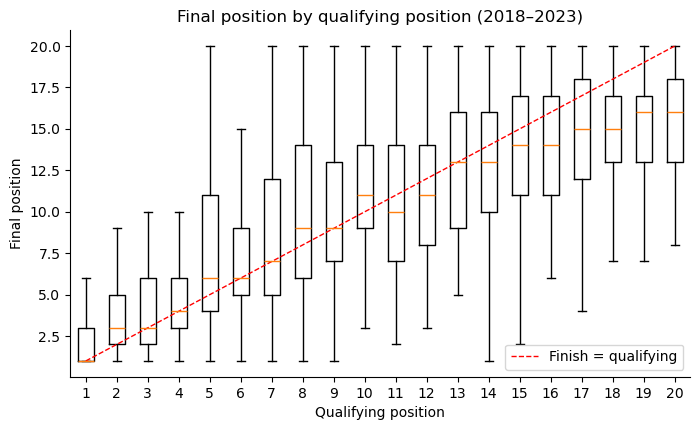

Correlation qualifying–final: 0.61, grid–final: 0.59, qualifying–grid: 0.95
Finished exactly where they started: 15.2%;  moved 5+ places: 30.0%


In [7]:
positions = range(1, 21)
fig, ax = plt.subplots()
ax.boxplot([development.loc[development["qualifying_position"] == p, "final_position"] for p in positions],
           positions=list(positions), showfliers=False)
ax.plot([1, 20], [1, 20], "r--", linewidth=1, label="Finish = qualifying")
ax.set_xlabel("Qualifying position")
ax.set_ylabel("Final position")
ax.set_title("Final position by qualifying position (2018–2023)")
ax.legend()
fig.savefig(FIGURES_DIR / "01_qualifying_vs_final.png", dpi=150, bbox_inches="tight")
plt.show()

gained = development["grid_position"] - development["final_position"]
print(f"Correlation qualifying–final: {development['qualifying_position'].corr(development['final_position']):.2f}, "
      f"grid–final: {development['grid_position'].corr(development['final_position']):.2f}, "
      f"qualifying–grid: {development['qualifying_position'].corr(development['grid_position']):.2f}")
print(f"Finished exactly where they started: {(gained == 0).mean():.1%};  moved 5+ places: {(gained.abs() >= 5).mean():.1%}")

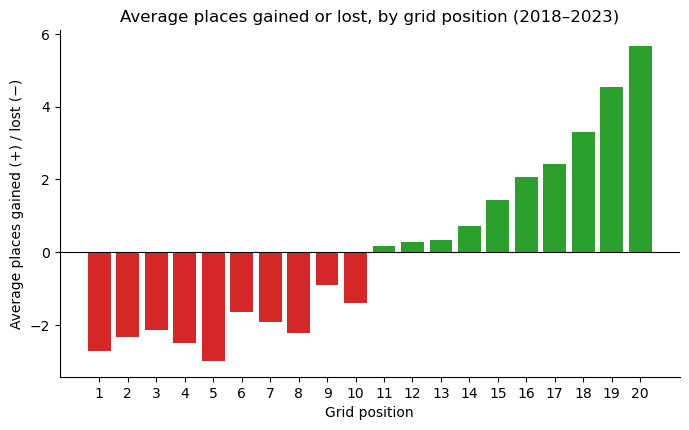

In [8]:
gain_by_grid = (development.assign(gained=gained)
                .query("grid_position <= 20").groupby("grid_position")["gained"].mean())
fig, ax = plt.subplots()
ax.bar(gain_by_grid.index, gain_by_grid, color=["tab:green" if g > 0 else "tab:red" for g in gain_by_grid])
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(range(1, 21))
ax.set_xlabel("Grid position")
ax.set_ylabel("Average places gained (+) / lost (−)")
ax.set_title("Average places gained or lost, by grid position (2018–2023)")
fig.savefig(FIGURES_DIR / "02_places_gained_by_grid.png", dpi=150, bbox_inches="tight")
plt.show()

Qualifying position has a slightly stronger correlation with final position than grid position (0.61 vs. 0.59), while qualifying and grid position are highly correlated with each other (0.95). Only 15.2% of drivers finish in the same position as their starting grid, while 30.0% move by at least five places.

The graph also shows a clear regression-to-the-middle pattern: drivers starting near the front tend to lose places on average, while drivers starting further back tend to gain places. Some of this is expected because finishing position is bounded between P1 and the last classified position.

## 7. Baseline Models

Before training ML models, I evaluated a few simple baselines using information available before the race.

The baselines use:
- Grid position
- Qualifying position
- Driver's average finishing position over the previous 5 races
- Constructor's average finishing position over the previous 5 races

I also fitted a Linear Regression model using grid position alone.

### Evaluation metrics

- **MAE:** Mean Absolute Error in finishing positions.
- **Median AE:** Median absolute error.
- **Within ±3 / ±5:** Percentage of predictions within 3 or 5 positions of the actual result.
- **Mean error:** Average of `(predicted position - actual position)`.
- **Spearman correlation:** Correlation between predicted and actual finishing order within each race.

In [9]:
def evaluate_predictions(frame, predicted):
    actual = frame[TARGET].to_numpy()
    predicted = np.asarray(predicted, dtype=float)
    error = predicted - actual
    ranked = pd.DataFrame({"race": frame["season"] * 100 + frame["round"], "actual": actual, "predicted": predicted})
    race_spearman = [g["predicted"].corr(g["actual"], method="spearman") for _, g in ranked.groupby("race")]
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "Median AE": median_absolute_error(actual, predicted),
        "Within ±3 (%)": 100 * np.mean(np.abs(error) <= 3),
        "Within ±5 (%)": 100 * np.mean(np.abs(error) <= 5),
        "Mean error": error.mean(),
        "Spearman (mean)": np.nanmean(race_spearman),
    }

BASELINES = {
    "Baseline: grid position": "grid_position",
    "Baseline: qualifying position": "qualifying_position",
    "Baseline: driver form (last 5)": "driver_avg_finish_last_5",
    "Baseline: constructor form (last 5)": "constructor_avg_finish_last_5",
}
validation_results = {name: evaluate_predictions(valid, valid[column]) for name, column in BASELINES.items()}

grid_line = LinearRegression().fit(train[["grid_position"]], train[TARGET])
validation_results["Linear Regression (grid only)"] = evaluate_predictions(valid, grid_line.predict(valid[["grid_position"]]))
print(f"Grid-only line: final ≈ {grid_line.coef_[0]:.2f} × grid + {grid_line.intercept_:.2f}")

print("\nValidation (2023):")
pd.DataFrame(validation_results).T.round(2)

Grid-only line: final ≈ 0.59 × grid + 4.27

Validation (2023):


,MAE,Median AE,Within ±3 (%),Within ±5 (%),Mean error,Spearman (mean)
Baseline: grid position,3.75,3.00,59.55,77.05,0.00,0.59
Baseline: qualifying position,3.68,3.00,61.14,78.41,-0.01,0.60
Baseline: driver form (last 5),3.68,2.80,53.41,75.45,-0.02,0.55
Baseline: constructor form (last 5),3.66,3.05,50.00,76.59,0.00,0.56
Linear Regression (grid only),3.67,3.23,48.41,75.68,-0.02,0.59


In 2023, the four baseline methods gave similar results, with MAE between 3.66 and 3.75. Qualifying and grid position performed slightly better than the recent-form baselines. The grid-only linear model had a similar MAE but did not improve on directly using grid position.

## 8. Feature Engineering

I used two feature sets to compare the original features with additional consistency and reliability information.

### V1 — Original features

The original feature set contains:
- Driver, constructor and circuit
- Season
- Qualifying and grid position
- Driver's average finishing position over the previous 5 races
- Driver's average qualifying position over the previous 5 races
- Constructor's average finishing position over the previous 5 races
- Driver and constructor points before the race

### V2 — Additional features

V2 adds four features calculated from the previous 5 races:
- Driver finishing-position standard deviation
- Driver qualifying-position standard deviation
- Driver non-finish rate
- Constructor non-finish rate

These features measure consistency and recent reliability.

Categorical variables are one-hot encoded. Missing numerical values are handled using a median imputer fitted on the training data.



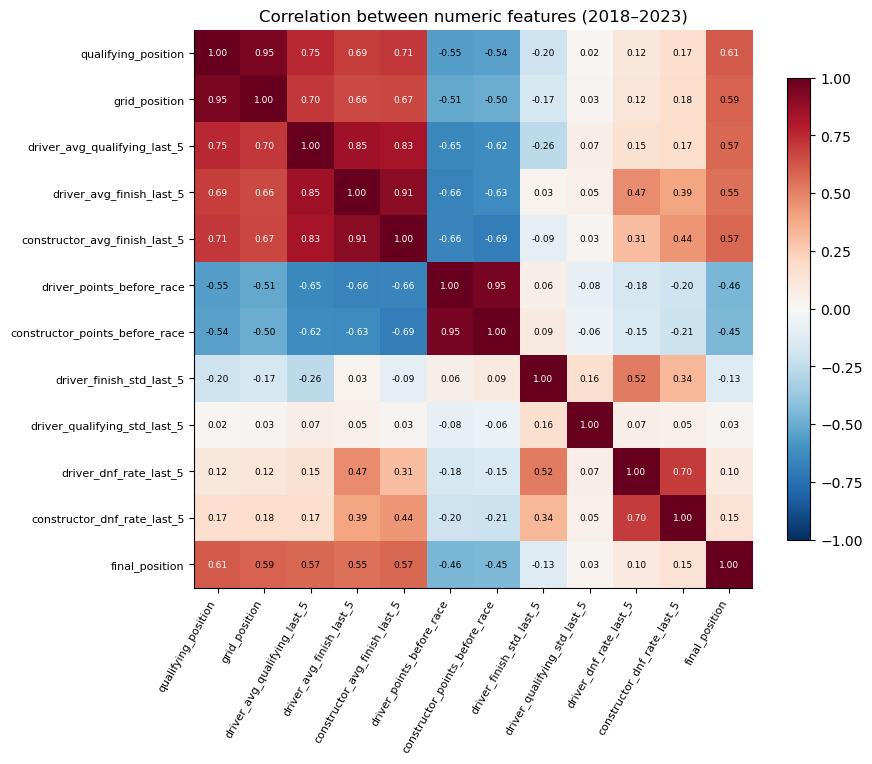

In [10]:
heatmap_features = ["qualifying_position", "grid_position", "driver_avg_qualifying_last_5",
                    "driver_avg_finish_last_5", "constructor_avg_finish_last_5",
                    "driver_points_before_race", "constructor_points_before_race"] + NEW_NUMERIC + [TARGET]
correlation = development[heatmap_features].corr()

fig, ax = plt.subplots(figsize=(9, 7.5))
image = ax.imshow(correlation, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(heatmap_features)), heatmap_features, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(heatmap_features)), heatmap_features, fontsize=8)
for i in range(len(heatmap_features)):
    for j in range(len(heatmap_features)):
        ax.text(j, i, f"{correlation.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6.5,
                color="white" if abs(correlation.iloc[i, j]) > 0.6 else "black")
fig.colorbar(image, ax=ax, shrink=0.8)
ax.set_title("Correlation between numeric features (2018–2023)")
fig.savefig(FIGURES_DIR / "03_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

Grid and qualifying position are highly correlated (0.95), while the recent driver and constructor form features are also strongly correlated with each other. This means several features contain overlapping information.

The DNF-rate features have relatively weak correlation with final position (0.10 for driver DNF rate and 0.15 for constructor DNF rate). Correlation measures association, not causation, so these values are used only to understand relationships between the variables.

## 9. Linear Regression


In [11]:
def make_pipeline(model, feature_list):
    numeric = [f for f in feature_list if f not in CATEGORICAL_FEATURES]
    preprocessing = ColumnTransformer(
        transformers=[
            ("one_hot", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
            ("num", SimpleImputer(strategy="median"), numeric),   # median learned from training data only
        ],
        sparse_threshold=0,   # dense output (HistGradientBoosting needs it)
    )
    return Pipeline([("preprocessing", preprocessing), ("model", model)])


candidates = []   # every configuration tried, scored on 2023 only

def try_candidate(family, model, settings=""):
    for set_name, feature_list in FEATURE_SETS.items():
        pipeline = make_pipeline(clone(model), feature_list).fit(train[feature_list], train[TARGET])
        candidates.append({
            "family": family, "settings": settings, "feature set": set_name,
            "train MAE": mean_absolute_error(train[TARGET], pipeline.predict(train[feature_list])),
            "validation MAE": mean_absolute_error(valid[TARGET], pipeline.predict(valid[feature_list])),
            "model": model, "features": feature_list,
        })

def show_candidates(family):
    table = pd.DataFrame([c for c in candidates if c["family"] == family])
    return table[["settings", "feature set", "train MAE", "validation MAE"]].sort_values("validation MAE").round(3)

try_candidate("Linear Regression", LinearRegression())
show_candidates("Linear Regression")

,settings,feature set,train MAE,validation MAE
0,,V1 (original 11),3.251,3.525
1,,V2 (+ consistency/reliability),3.248,3.533


In [12]:
v1 = FEATURE_SETS["V1 (original 11)"]
weights_pipeline = make_pipeline(LinearRegression(), v1).fit(train[v1], train[TARGET])
numeric_v1 = [f for f in v1 if f not in CATEGORICAL_FEATURES]
pd.Series(weights_pipeline.named_steps["model"].coef_[-len(numeric_v1):], index=numeric_v1, name="weight (V1)").round(3)

season                            0.153
qualifying_position               0.203
grid_position                     0.152
driver_avg_finish_last_5         -0.175
driver_avg_qualifying_last_5      0.074
constructor_avg_finish_last_5     0.097
driver_points_before_race        -0.008
constructor_points_before_race    0.002
Name: weight (V1), dtype: float64

## 9. Model Candidates

I compared multiple model families using the same temporal train/validation split. Each model was evaluated with both feature sets:

- **V1:** original features
- **V2:** original features + consistency and reliability features

Model and feature-set selection is based only on the 2023 validation set. The 2024–2025 test set is kept untouched until the final evaluation.

## 10. Random Forest


In [13]:
for max_depth in [6, 10, None]:
    for min_samples_leaf in [5, 20]:
        try_candidate("Random Forest",
                      RandomForestRegressor(n_estimators=300, max_depth=max_depth, min_samples_leaf=min_samples_leaf,
                                            random_state=42, n_jobs=-1),
                      f"max_depth={max_depth}, min_samples_leaf={min_samples_leaf}")
show_candidates("Random Forest")

,settings,feature set,train MAE,validation MAE
8,"max_depth=None, min_samples_leaf=5",V1 (original 11),2.370,3.336
4,"max_depth=10, min_samples_leaf=5",V1 (original 11),2.631,3.343
2,"max_depth=6, min_samples_leaf=20",V1 (original 11),3.139,3.362
0,"max_depth=6, min_samples_leaf=5",V1 (original 11),3.024,3.364
7,"max_depth=10, min_samples_leaf=20",V2 (+ consistency/reliability),3.033,3.366
11,"max_depth=None, min_samples_leaf=20",V2 (+ consistency/reliability),3.031,3.366
3,"max_depth=6, min_samples_leaf=20",V2 (+ consistency/reliability),3.118,3.366
10,"max_depth=None, min_samples_leaf=20",V1 (original 11),3.064,3.366
6,"max_depth=10, min_samples_leaf=20",V1 (original 11),3.067,3.367
5,"max_depth=10, min_samples_leaf=5",V2 (+ consistency/reliability),2.558,3.387


## 11. Gradient Boosting & HistGradientBoosting

In [14]:
try_candidate("Gradient Boosting", GradientBoostingRegressor(random_state=42), "default")
for learning_rate in [0.05, 0.1]:
    for max_leaf_nodes in [15, 31]:
        try_candidate("HistGradientBoosting",
                      HistGradientBoostingRegressor(learning_rate=learning_rate, max_leaf_nodes=max_leaf_nodes,
                                                    max_iter=200, min_samples_leaf=20, early_stopping=False,
                                                    random_state=42),
                      f"learning_rate={learning_rate}, max_leaf_nodes={max_leaf_nodes}")
pd.concat({"Gradient Boosting": show_candidates("Gradient Boosting"),
           "HistGradientBoosting": show_candidates("HistGradientBoosting")})

settings                     feature set  train MAE  validation MAE
Gradient Boosting    0                                default                V1 (original 11)      2.932           3.378
                     1                                default  V2 (+ consistency/reliability)      2.914           3.458
HistGradientBoosting 0  learning_rate=0.05, max_leaf_nodes=15                V1 (original 11)      2.664           3.311
                     2  learning_rate=0.05, max_leaf_nodes=31                V1 (original 11)      2.148           3.418
                     4   learning_rate=0.1, max_leaf_nodes=15                V1 (original 11)      2.286           3.422
                     1  learning_rate=0.05, max_leaf_nodes=15  V2 (+ consistency/reliability)      2.569           3.444
                     6   learning_rate=0.1, max_leaf_nodes=31                V1 (original 11)      1.634           3.514
                     3  learning_rate=0.05, max_leaf_nodes=31  V2 (+ consistency/reliability)      1.964           3.542
                     5   learning_rate=0.1, max_leaf_nodes=15  V2 (+ consistency/reliability)      2.118           3.585
                     7   learning_rate=0.1, max_leaf_nodes=31  V2 (+ consistency/reliability)      1.365           3.628

## 12. Model Evaluation

The models are evaluated using the 2023 validation set for selection and the 2024–2025 seasons for the final test.
A walk-forward check is also used to see whether model performance is reasonably consistent across earlier seasons.

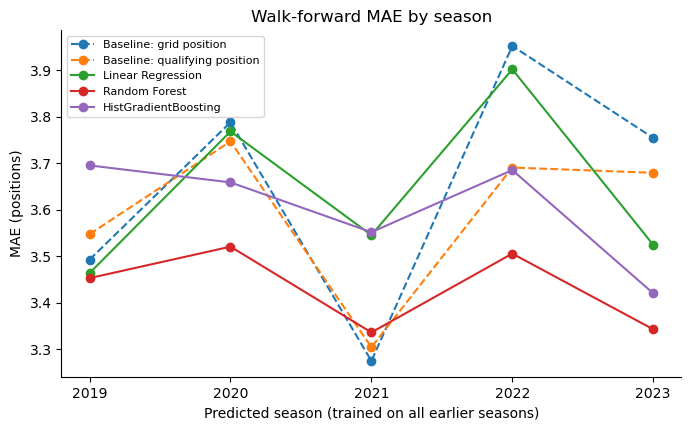

Seasons where the best ML model beat the grid baseline: 4 of 5


,Baseline: grid position,Baseline: qualifying position,Linear Regression,Random Forest,HistGradientBoosting
2019,3.49,3.55,3.46,3.45,3.70
2020,3.79,3.75,3.77,3.52,3.66
2021,3.28,3.30,3.55,3.34,3.55
2022,3.95,3.69,3.90,3.51,3.69
2023,3.75,3.68,3.52,3.34,3.42


In [15]:
walk_forward_models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=300, max_depth=10, min_samples_leaf=5, random_state=42, n_jobs=-1),
    "HistGradientBoosting": HistGradientBoostingRegressor(early_stopping=False, random_state=42),
}
walk_forward = {}
for season in range(2019, 2024):
    past, current = data[data["season"] < season], data[data["season"] == season]
    scores = {"Baseline: grid position": mean_absolute_error(current[TARGET], current["grid_position"]),
              "Baseline: qualifying position": mean_absolute_error(current[TARGET], current["qualifying_position"])}
    for name, model in walk_forward_models.items():
        pipeline = make_pipeline(clone(model), v1).fit(past[v1], past[TARGET])
        scores[name] = mean_absolute_error(current[TARGET], pipeline.predict(current[v1]))
    walk_forward[season] = scores
walk_forward = pd.DataFrame(walk_forward).T
walk_forward.to_csv(RESULTS_DIR / "walk_forward_mae.csv")

fig, ax = plt.subplots()
for name in walk_forward.columns:
    ax.plot(walk_forward.index, walk_forward[name], marker="o", label=name,
            linestyle="--" if name.startswith("Baseline") else "-")
ax.set_xticks(walk_forward.index)
ax.set_xlabel("Predicted season (trained on all earlier seasons)")
ax.set_ylabel("MAE (positions)")
ax.set_title("Walk-forward MAE by season")
ax.legend(fontsize=8)
fig.savefig(FIGURES_DIR / "04_walk_forward_mae.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Seasons where the best ML model beat the grid baseline: "
      f"{(walk_forward[list(walk_forward_models)].min(axis=1) < walk_forward['Baseline: grid position']).sum()} of 5")
walk_forward.round(2)

Across 2019–2023, an ML model achieved a lower MAE than the grid-position baseline in 4 of the 5 seasons. Performance varies between seasons, and no single model is consistently best in every year.

### 12.2 Model selection on the 2023 validation season

For each model family, the configuration and feature set with the lowest 2023 MAE is kept. The overall **selected model** is the family with the lowest 2023 MAE.

In [16]:
candidate_table = pd.DataFrame(candidates)
best_per_family = candidate_table.loc[candidate_table.groupby("family")["validation MAE"].idxmin()].sort_values("validation MAE")
selected = best_per_family.iloc[0]
SELECTED_NAME = selected["family"]

print(f"Selected model: {SELECTED_NAME} ({selected['settings']}, {selected['feature set']}), "
      f"validation MAE {selected['validation MAE']:.3f}")
print(f"Grid baseline validation MAE: {validation_results['Baseline: grid position']['MAE']:.3f}")

feature_set_effect = candidate_table.groupby(["family", "feature set"])["validation MAE"].min().unstack().round(3)
print("\nBest validation MAE per family and feature set:")
print(feature_set_effect.to_string())

best_per_family[["family", "settings", "feature set", "train MAE", "validation MAE"]].round(3)

Selected model: HistGradientBoosting (learning_rate=0.05, max_leaf_nodes=15, V1 (original 11)), validation MAE 3.311
Grid baseline validation MAE: 3.755

Best validation MAE per family and feature set:
feature set           V1 (original 11)  V2 (+ consistency/reliability)
family                                                                
Gradient Boosting                3.378                           3.458
HistGradientBoosting             3.311                           3.444
Linear Regression                3.525                           3.533
Random Forest                    3.336                           3.366


,family,settings,feature set,train MAE,validation MAE
16,HistGradientBoosting,"learning_rate=0.05, max_leaf_nodes=15",V1 (original 11),2.664,3.311
10,Random Forest,"max_depth=None, min_samples_leaf=5",V1 (original 11),2.370,3.336
14,Gradient Boosting,default,V1 (original 11),2.932,3.378
0,Linear Regression,,V1 (original 11),3.251,3.525


HistGradientBoosting with V1 gave the lowest 2023 validation MAE (3.325), followed closely by Random Forest (3.336). The selected configuration is therefore HistGradientBoosting with learning rate 0.05, 15 leaves, and V1 features.

For all model families, V2 performed slightly worse than V1 on the 2023 validation set, so the final model uses V1.

### 12.3 Final test evaluation (2024–2025)

Each family's selected configuration is refit on 2018–2023 and evaluated **once** on the test seasons, alongside the baselines. Nothing is changed after this point.

In [17]:
final_pipelines, test_predictions = {}, {}
for _, row in best_per_family.iterrows():
    pipeline = make_pipeline(clone(row["model"]), row["features"]).fit(development[row["features"]], development[TARGET])
    final_pipelines[row["family"]] = (pipeline, row["features"])
    test_predictions[row["family"]] = pipeline.predict(test[row["features"]])

grid_line_final = LinearRegression().fit(development[["grid_position"]], development[TARGET])
test_predictions["Linear Regression (grid only)"] = grid_line_final.predict(test[["grid_position"]])
for name, column in BASELINES.items():
    test_predictions[name] = test[column].to_numpy()

test_results = pd.DataFrame({name: evaluate_predictions(test, pred) for name, pred in test_predictions.items()}).T
test_results = test_results.sort_values("MAE")
test_results.index = [f"{name}  ← selected on 2023" if name == SELECTED_NAME else name for name in test_results.index]
test_results.round(2).to_csv(RESULTS_DIR / "test_metrics.csv")

selected_pipeline, selected_features = final_pipelines[SELECTED_NAME]
joblib.dump(selected_pipeline, MODELS_DIR / "final_model.joblib", compress=3)

per_season = pd.DataFrame({name: pd.Series(np.abs(pred - test[TARGET].to_numpy()), index=test.index)
                           .groupby(test["season"]).mean()
                           for name, pred in test_predictions.items()}).T
per_season.columns = [f"MAE {season}" for season in per_season.columns]
print("Grid-baseline MAE in earlier seasons:",
      data.assign(err=(data["grid_position"] - data[TARGET]).abs()).groupby("season")["err"].mean().round(2).to_dict())
print(f"Non-finish rate: 2018–2023 {development['did_not_finish'].mean():.1%}, 2024–2025 {test['did_not_finish'].mean():.1%}")
per_season.index = [f"{n}  ← selected on 2023" if n == SELECTED_NAME else n for n in per_season.index]
test_results.round(2).join(per_season.round(2))

Grid-baseline MAE in earlier seasons: {2018: 3.82, 2019: 3.49, 2020: 3.79, 2021: 3.28, 2022: 3.95, 2023: 3.75, 2024: 2.89, 2025: 3.34}
Non-finish rate: 2018–2023 16.0%, 2024–2025 11.9%


,MAE,Median AE,Within ±3 (%),Within ±5 (%),Mean error,Spearman (mean),MAE 2024,MAE 2025
Baseline: qualifying position,3.08,2.00,68.06,82.78,-0.02,0.70,2.83,3.34
Baseline: grid position,3.12,2.00,67.85,82.36,0.00,0.69,2.89,3.34
Random Forest,3.26,2.75,55.53,80.17,0.00,0.67,3.12,3.40
Linear Regression (grid only),3.30,2.83,52.30,81.52,-0.01,0.69,3.12,3.47
Gradient Boosting,3.30,2.79,54.07,80.17,-0.07,0.67,3.15,3.45
Linear Regression,3.36,2.79,52.92,78.39,0.10,0.66,3.12,3.61
HistGradientBoosting ← selected on 2023,3.42,2.92,51.36,78.50,-0.08,0.64,3.29,3.55
Baseline: driver form (last 5),3.62,3.00,51.57,75.57,-0.03,0.57,3.40,3.85
Baseline: constructor form (last 5),3.69,3.00,51.04,73.28,-0.03,0.56,3.39,3.98


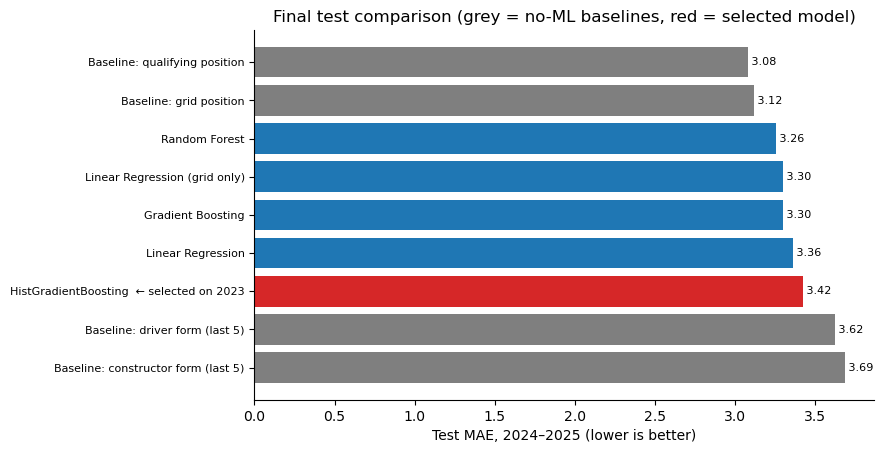

In [18]:
fig, ax = plt.subplots(figsize=(8, 4.8))
plot_data = test_results["MAE"].sort_values(ascending=False)
colors = ["tab:gray" if "Baseline" in name else ("tab:red" if "selected" in name else "tab:blue") for name in plot_data.index]
ax.barh(plot_data.index, plot_data, color=colors)
for i, value in enumerate(plot_data):
    ax.text(value, i, f" {value:.2f}", va="center", fontsize=8)
ax.set_xlabel("Test MAE, 2024–2025 (lower is better)")
ax.set_title("Final test comparison (grey = no-ML baselines, red = selected model)")
ax.tick_params(axis="y", labelsize=8)
fig.savefig(FIGURES_DIR / "05_test_mae_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

### Final test results

On the 2024–2025 test set, the starting-position baselines remain strong. Qualifying position has an MAE of 3.08 and grid position 3.12. Among the ML models, Random Forest achieves an MAE of 3.26, while the model selected using 2023 validation, HistGradientBoosting, achieves 3.41.
This shows that the model selected on the validation season does not necessarily outperform the simple starting-position baselines on later seasons.
The per-season results show that performance varies across seasons. In 2024, the grid-position baseline achieves an MAE of 2.89, while in 2025 the difference between Random Forest and the grid baseline is small.
Overall, the additional driver, constructor and historical-form features do not consistently improve prediction over the starting grid.

### 12.4 Actual vs predicted

Mean actual position: 10.48   mean predicted: 10.40   mean signed error: -0.08
Spread (std) of actual positions: 5.76   of predictions: 3.75
Predictions range: -0.2 – 16.8


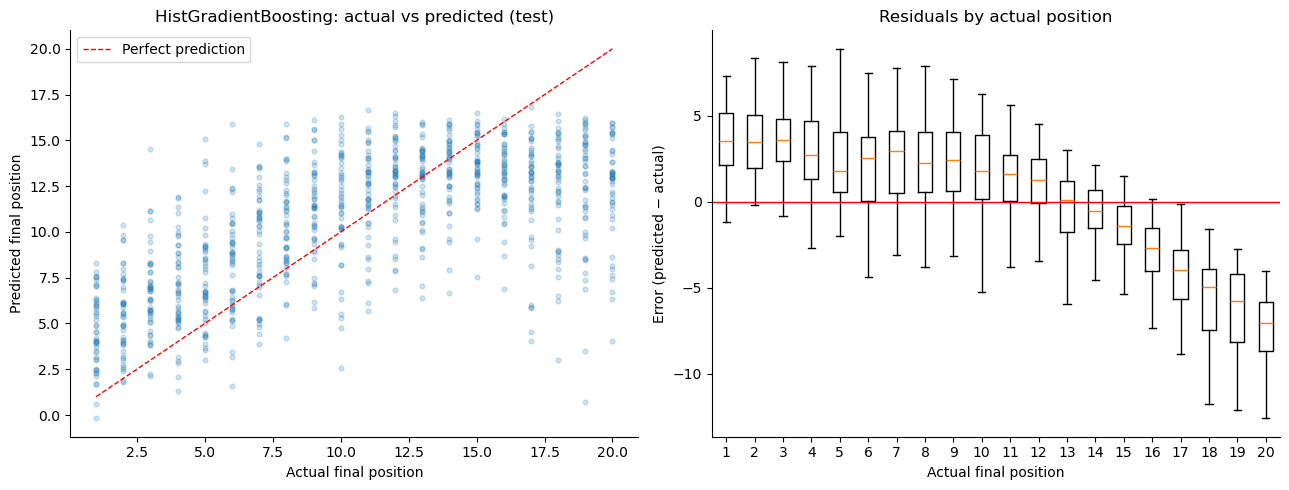

In [19]:
selected_pred = test_predictions[SELECTED_NAME]
actual = test[TARGET].to_numpy()
print(f"Mean actual position: {actual.mean():.2f}   mean predicted: {selected_pred.mean():.2f}   "
      f"mean signed error: {(selected_pred - actual).mean():+.2f}")
print(f"Spread (std) of actual positions: {actual.std():.2f}   of predictions: {selected_pred.std():.2f}")
print(f"Predictions range: {selected_pred.min():.1f} – {selected_pred.max():.1f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(actual, selected_pred, alpha=0.2, s=12)
axes[0].plot([1, 20], [1, 20], "r--", linewidth=1, label="Perfect prediction")
axes[0].set_xlabel("Actual final position")
axes[0].set_ylabel("Predicted final position")
axes[0].set_title(f"{SELECTED_NAME}: actual vs predicted (test)")
axes[0].legend()

residuals = pd.DataFrame({"actual": actual, "error": selected_pred - actual})
axes[1].boxplot([residuals.loc[residuals["actual"] == p, "error"] for p in range(1, 21)],
                positions=list(range(1, 21)), showfliers=False)
axes[1].axhline(0, color="red", linewidth=1)
axes[1].set_xlabel("Actual final position")
axes[1].set_ylabel("Error (predicted − actual)")
axes[1].set_title("Residuals by actual position")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "06_actual_vs_predicted_residuals.png", dpi=150, bbox_inches="tight")
plt.show()

The model's mean prediction is close to the mean actual finishing position, with a small overall signed error. However, the predicted positions have a smaller spread than the actual positions.
The residual plot shows a systematic pattern: drivers finishing near the front tend to be predicted slightly too far back, while drivers finishing near the back tend to be predicted too far forward. This indicates that the regression model tends to pull extreme finishing positions toward the middle.
This compression is a limitation of the regression approach, particularly for predicting very high or very low finishing positions.

## 13. Feature Importance

Feature importance is examined using the Random Forest model refit on the 2018–2023 development set. Random Forest provides two complementary measures:

- **Impurity importance:** the share of training error reduction attributed to each feature. This can be affected by correlated features.
- **Permutation importance:** the increase in test MAE when a feature is randomly shuffled. This measures how much predictive performance depends on that feature on unseen data.

Neither measure is causal. They describe which features the model uses for prediction, not what causes finishing position.

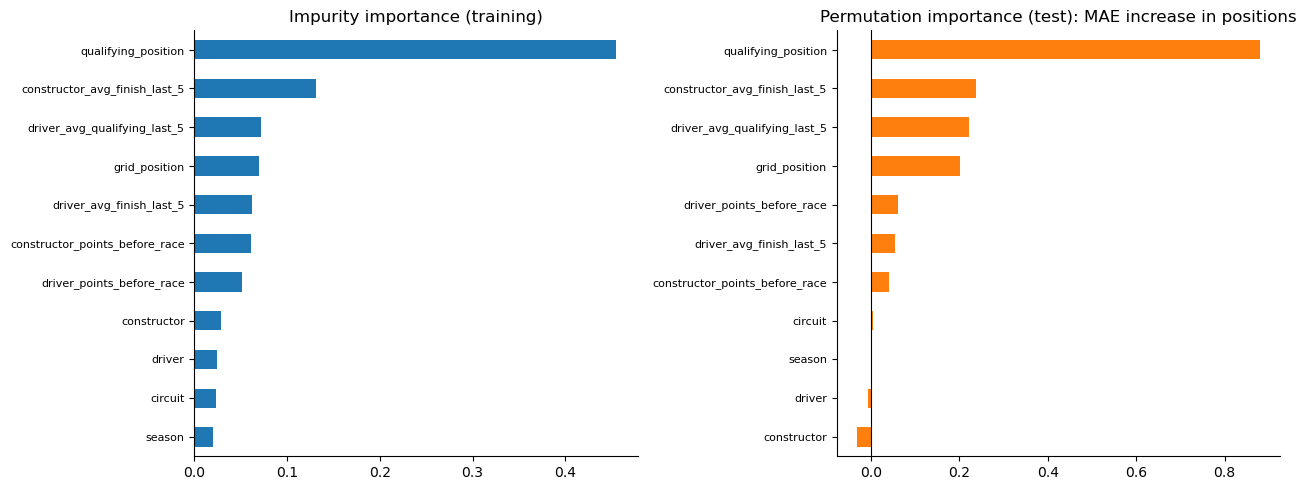

,impurity share,permutation: test MAE increase
qualifying_position,0.455,0.880
constructor_avg_finish_last_5,0.132,0.237
driver_avg_qualifying_last_5,0.071,0.222
grid_position,0.069,0.200
driver_avg_finish_last_5,0.062,0.054
constructor_points_before_race,0.062,0.040
driver_points_before_race,0.051,0.061
constructor,0.029,-0.032
driver,0.025,-0.008
circuit,0.024,0.003


In [20]:
forest_pipeline, forest_features = final_pipelines["Random Forest"]
encoded = forest_pipeline.named_steps["preprocessing"].get_feature_names_out()

def original_feature(encoded_name):
    step, name = encoded_name.split("__", 1)
    if step == "num":
        return name
    return next(c for c in CATEGORICAL_FEATURES if name.startswith(c + "_"))

impurity = (pd.Series(forest_pipeline.named_steps["model"].feature_importances_, index=encoded)
            .groupby(original_feature).sum())
permutation = permutation_importance(forest_pipeline, test[forest_features], test[TARGET], n_repeats=10,
                                     random_state=42, scoring="neg_mean_absolute_error", n_jobs=-1)
importance = pd.DataFrame({
    "impurity share": impurity,
    "permutation: test MAE increase": pd.Series(permutation.importances_mean, index=forest_features),
}).sort_values("impurity share", ascending=False)
importance.round(3).to_csv(RESULTS_DIR / "feature_importance.csv")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
importance["impurity share"].sort_values().plot.barh(ax=axes[0], color="tab:blue")
axes[0].set_title("Impurity importance (training)")
importance["permutation: test MAE increase"].sort_values().plot.barh(ax=axes[1], color="tab:orange")
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title("Permutation importance (test): MAE increase in positions")
for ax in axes:
    ax.tick_params(axis="y", labelsize=8)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "07_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()
importance.round(3)

The model relies most heavily on qualifying position, followed by constructor recent form, driver recent qualifying performance and grid position.
Qualifying position has the largest importance in both measures. Grid position is slightly less important, partly because qualifying and grid position are highly correlated.
The importance values should not be interpreted causally. They indicate which information the Random Forest uses most for prediction on this dataset.

## 14. Error Analysis


By starting-position group:
            rows   MAE  mean_error  dnf_share
grid_group                                   
P1–3         144  3.40        1.26       0.05
P4–10        336  3.54        0.59       0.10
P11–15       240  3.54       -0.79       0.17
P16–20       238  3.16       -1.11       0.15


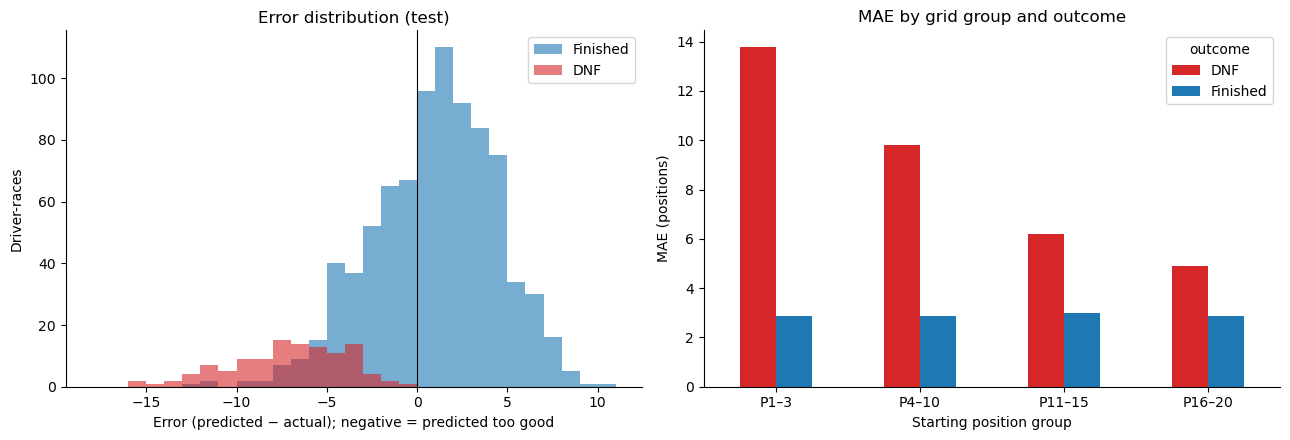

In [21]:
errors = test[["season", "race_name", "driver", "constructor", "qualifying_position", "grid_position",
               "final_position", "status", "did_not_finish"]].copy()
errors["predicted"] = selected_pred.round(1)
errors["error"] = (selected_pred - errors["final_position"]).round(1)
errors["abs_error"] = errors["error"].abs()
errors["grid_group"] = pd.cut(errors["grid_position"], bins=[0, 3, 10, 15, 20], labels=["P1–3", "P4–10", "P11–15", "P16–20"])
errors["outcome"] = np.where(errors["did_not_finish"], "DNF", "Finished")

by_group = errors.groupby("grid_group", observed=True).agg(
    rows=("error", "size"), MAE=("abs_error", "mean"), mean_error=("error", "mean"), dnf_share=("did_not_finish", "mean"))
print("By starting-position group:")
print(by_group.round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
bins = np.arange(-18, 12, 1)
for outcome, color in [("Finished", "tab:blue"), ("DNF", "tab:red")]:
    axes[0].hist(errors.loc[errors["outcome"] == outcome, "error"], bins=bins, alpha=0.6, color=color, label=outcome)
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_xlabel("Error (predicted − actual); negative = predicted too good")
axes[0].set_ylabel("Driver-races")
axes[0].set_title("Error distribution (test)")
axes[0].legend()

group_mae = errors.groupby(["grid_group", "outcome"], observed=True)["abs_error"].mean().unstack()
group_mae.plot.bar(ax=axes[1], color={"Finished": "tab:blue", "DNF": "tab:red"}, rot=0)
axes[1].set_xlabel("Starting position group")
axes[1].set_ylabel("MAE (positions)")
axes[1].set_title("MAE by grid group and outcome")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "08_error_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

In [22]:
print("10 largest errors:")
errors.sort_values("abs_error", ascending=False).head(10)[
    ["season", "race_name", "driver", "grid_position", "final_position", "predicted", "error", "status"]]

10 largest errors:


,season,race_name,driver,grid_position,final_position,predicted,error,status
2558,2024,Australian Grand Prix,Max Verstappen,1,19,0.7,-18.3,Retired
2978,2024,Abu Dhabi Grand Prix,Sergio Pérez,10,20,4.1,-15.9,Retired
3416,2025,Las Vegas Grand Prix,Lando Norris,1,19,3.5,-15.5,Disqualified
3275,2025,Dutch Grand Prix,Lando Norris,2,18,3.0,-15.0,Retired
2878,2024,United States Grand Prix,Lewis Hamilton,17,20,6.3,-13.7,Retired
2938,2024,Las Vegas Grand Prix,Pierre Gasly,3,20,6.7,-13.3,Retired
2955,2024,Qatar Grand Prix,Sergio Pérez,9,17,4.0,-13.0,Retired
2778,2024,Belgian Grand Prix,George Russell,6,20,7.4,-12.6,Disqualified
2835,2024,Azerbaijan Grand Prix,Sergio Pérez,4,17,4.5,-12.5,Retired
2718,2024,Austrian Grand Prix,Lando Norris,2,20,7.6,-12.4,Lapped


The largest errors are concentrated among non-finishes. The model generally predicts finishing positions closer to the starting order, so unexpected retirements can produce very large errors.
Errors also differ by starting position: front-row drivers tend to be predicted slightly behind their eventual finishing position when they finish, while back-markers tend to be predicted slightly ahead.
These patterns suggest that race-day events not included in the dataset are an important source of remaining error.

## 15. DNF Analysis


In [23]:
grid_error = test["grid_position"].to_numpy() - actual
comparison_rows = {}
for name, error in [(SELECTED_NAME, selected_pred - actual), ("Baseline: grid position", grid_error)]:
    frame = pd.DataFrame({"error": error, "dnf": test["did_not_finish"].to_numpy()})
    large = frame[frame["error"].abs() >= 5]
    comparison_rows[name] = {
        "MAE finished": frame.loc[~frame["dnf"], "error"].abs().mean(),
        "MAE DNF": frame.loc[frame["dnf"], "error"].abs().mean(),
        "mean error finished": frame.loc[~frame["dnf"], "error"].mean(),
        "mean error DNF": frame.loc[frame["dnf"], "error"].mean(),
        "errors ≥5 places (%)": 100 * len(large) / len(frame),
        "of which DNF (%)": 100 * large["dnf"].mean(),
        "share of total abs. error from DNFs (%)": 100 * frame.loc[frame["dnf"], "error"].abs().sum() / frame["error"].abs().sum(),
    }
print(f"Test DNF rate: {test['did_not_finish'].mean():.1%} ({test['did_not_finish'].sum()} of {len(test)})")
pd.DataFrame(comparison_rows).T.round(2)

Test DNF rate: 11.9% (114 of 958)


,MAE finished,MAE DNF,mean error finished,mean error DNF,errors ≥5 places (%),of which DNF (%),share of total abs. error from DNFs (%)
HistGradientBoosting,2.90,7.28,0.90,-7.28,21.5,39.81,25.3
Baseline: grid position,2.64,6.63,0.86,-6.39,23.7,31.72,25.3


Non-finishes are 11.9% of test rows but produce **25% of all absolute error**, for both the selected model and the grid baseline. For the selected model, DNF MAE is 7.27 vs 2.89 for finishers, and 39.8% of its 5+ place errors are DNFs. Non-finishes do not explain the whole gap, though: **even among finishers the grid baseline is more accurate** (2.64 vs 2.89). Removing DNFs would not make the ML model win.

### Can non-finishes be predicted before the race?

A two-stage model was tested to determine whether explicitly predicting DNFs could reduce the large errors caused by non-finishes.

- **Stage 1:** a Random Forest classifier predicts the probability of a DNF using pre-race features.
- **Stage 2:** the selected regression model predicts finishing position for drivers who finish.
- **Combined prediction:** the DNF probability is used to combine the expected DNF position with the regression prediction.

The experiment is evaluated on the 2023 validation season before looking at the test set.

In [24]:
v2 = FEATURE_SETS["V2 (+ consistency/reliability)"]

def two_stage_fit_predict(fit_rows, predict_rows):
    classifier = make_pipeline(RandomForestClassifier(n_estimators=300, min_samples_leaf=20, random_state=42, n_jobs=-1), v2)
    classifier.fit(fit_rows[v2], fit_rows["did_not_finish"])
    finishers = fit_rows[~fit_rows["did_not_finish"]]
    regressor = make_pipeline(clone(selected["model"]), selected["features"]).fit(finishers[selected["features"]], finishers[TARGET])
    p_dnf = classifier.predict_proba(predict_rows[v2])[:, 1]
    dnf_position = fit_rows.loc[fit_rows["did_not_finish"], TARGET].mean()
    combined = p_dnf * dnf_position + (1 - p_dnf) * regressor.predict(predict_rows[selected["features"]])
    return p_dnf, combined

p_dnf_valid, two_stage_valid = two_stage_fit_predict(train, valid)
print(f"Stage 1 DNF classifier, 2023 ROC AUC: {roc_auc_score(valid['did_not_finish'], p_dnf_valid):.3f}")
print(f"  (for reference, driver DNF rate alone: {roc_auc_score(valid['did_not_finish'], valid['driver_dnf_rate_last_5'].fillna(0)):.3f}, "
      f"constructor DNF rate alone: {roc_auc_score(valid['did_not_finish'], valid['constructor_dnf_rate_last_5'].fillna(0)):.3f})")
print(f"Validation MAE: two-stage {mean_absolute_error(valid[TARGET], two_stage_valid):.3f} "
      f"vs selected single model {selected['validation MAE']:.3f}")

p_dnf_test, two_stage_test = two_stage_fit_predict(development, test)
print(f"\nTest (reported for completeness; two-stage adopted only if it won on 2023):")
print(f"  stage 1 ROC AUC: {roc_auc_score(test['did_not_finish'], p_dnf_test):.3f}")
pd.DataFrame({"Two-stage": evaluate_predictions(test, two_stage_test),
              SELECTED_NAME: evaluate_predictions(test, selected_pred)}).T.round(2)

Stage 1 DNF classifier, 2023 ROC AUC: 0.550
  (for reference, driver DNF rate alone: 0.494, constructor DNF rate alone: 0.530)
Validation MAE: two-stage 3.347 vs selected single model 3.311

Test (reported for completeness; two-stage adopted only if it won on 2023):
  stage 1 ROC AUC: 0.587


,MAE,Median AE,Within ±3 (%),Within ±5 (%),Mean error,Spearman (mean)
Two-stage,3.22,2.71,56.89,81.21,-0.24,0.68
HistGradientBoosting,3.42,2.92,51.36,78.50,-0.08,0.64


The DNF classifier performs only slightly better than chance on the validation season (ROC AUC = 0.550). The two-stage model also has a higher validation MAE than the selected single-stage model (3.347 vs 3.311).

Therefore, the two-stage approach is not adopted. The results suggest that the available pre-race features do not contain enough information to reliably identify which drivers will fail to finish.

## 16. Ranking Analysis

F1 results are a ranking. For each test race, the Spearman correlation between predicted and actual finishing order (1 = perfect order).

        Grid position  Qualifying position  HistGradientBoosting
mean            0.690                0.700                 0.645
median          0.725                0.745                 0.679
min             0.084                0.086                 0.036
max             0.964                0.961                 0.925

Races where HistGradientBoosting ranked the field better than the grid: 12 of 48


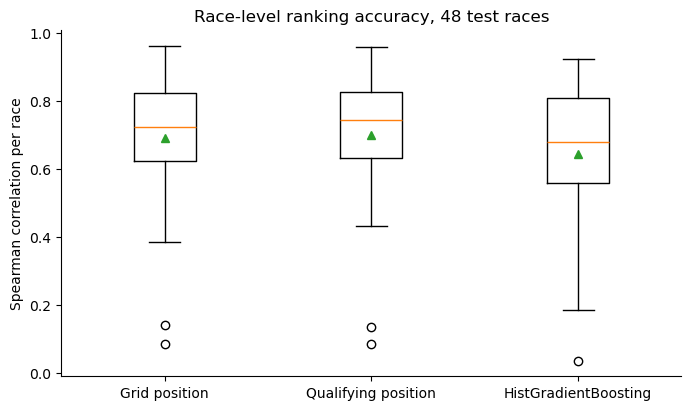

In [25]:
def race_spearman(predicted):
    frame = pd.DataFrame({"race": test["season"] * 100 + test["round"], "actual": actual, "predicted": predicted})
    return pd.Series({race: g["predicted"].corr(g["actual"], method="spearman") for race, g in frame.groupby("race")})

rank_scores = pd.DataFrame({
    "Grid position": race_spearman(test["grid_position"].to_numpy()),
    "Qualifying position": race_spearman(test["qualifying_position"].to_numpy()),
    SELECTED_NAME: race_spearman(selected_pred),
})
print(rank_scores.agg(["mean", "median", "min", "max"]).round(3).to_string())
print(f"\nRaces where {SELECTED_NAME} ranked the field better than the grid: "
      f"{(rank_scores[SELECTED_NAME] > rank_scores['Grid position']).sum()} of {len(rank_scores)}")

fig, ax = plt.subplots()
ax.boxplot([rank_scores[c] for c in rank_scores.columns], showmeans=True)
ax.set_xticks(range(1, len(rank_scores.columns) + 1), rank_scores.columns)
ax.set_ylabel("Spearman correlation per race")
ax.set_title(f"Race-level ranking accuracy, {len(rank_scores)} test races")
fig.savefig(FIGURES_DIR / "09_race_spearman.png", dpi=150, bbox_inches="tight")
plt.show()

Mean per-race Spearman: qualifying 0.700, grid 0.690, selected model 0.648 (medians 0.745, 0.725 and 0.686). The selected model ordered the field better than the grid in only 15 of 48 races. A rank correlation around 0.7 means the predicted order is broadly right but with several swaps per race. In the worst races (as low as ~0.08 for the grid), the actual order had little relation to the starting order.

## 17. Conclusions

- Finishing position can be predicted moderately well, with an MAE of about 3 positions.
- On 2024–2025, qualifying position (3.08 MAE) and grid position (3.12) outperformed the ML models.
- Qualifying position is the most important feature; recent driver and constructor form add limited information.
- The largest errors come from non-finishes, which are difficult to predict using pre-race data.
- Weather, strategy, safety cars and other race-day factors are missing and could improve future predictions.

**Bottom line:** Starting position already captures most of the available signal, while unexpected race events cause the largest prediction errors.

## 18. Limitations

- Non-finishes and race incidents are difficult to predict from pre-race data.
- Weather, safety cars, tyre/pit strategy and incidents are not included.
- Regulation and team changes reduce the usefulness of older historical data.
- Circuit-specific driver history is not explicitly modelled.
- Model selection uses only one validation season (2023).
- Regression predictions are not constrained to P1–P20.
- Sprint points are not included in the points features.

## 20. Inference: Predicting a Race

Sections 1–19 are the research: they train, select and evaluate the models. This section uses the **saved** model to predict new races, without retraining:

In [26]:
import prediction

deployed_model = prediction.load_model(MODELS_DIR / "final_model.joblib")
model_features = prediction.model_feature_names(deployed_model)
print("Saved model:", type(deployed_model.named_steps["model"]).__name__)
print("Features read from the saved model:", model_features)

assert model_features == list(selected_features), "saved model and notebook's selected model use different features"
assert np.allclose(deployed_model.predict(test[model_features]), selected_pred)
print("✓ The saved model reproduces the notebook's test predictions exactly.")

Saved model: HistGradientBoostingRegressor
Features read from the saved model: ['driver', 'constructor', 'circuit', 'season', 'qualifying_position', 'grid_position', 'driver_avg_finish_last_5', 'driver_avg_qualifying_last_5', 'constructor_avg_finish_last_5', 'driver_points_before_race', 'constructor_points_before_race']
✓ The saved model reproduces the notebook's test predictions exactly.


`predict_race` is the whole inference interface: one function taking the race information and the entry list. Its documentation:

In [27]:
help(prediction.predict_race)

Help on function predict_race in module prediction:

predict_race(
    race_info,
    qualifying_results,
    model=None,
    history=None,
    grid_same_as_qualifying=False,
    allow_duplicate_qualifying=False,
    return_features=False
)
    Predict a race from pre-race information.

    race_info: {"season": int, "circuit": str, "race_name": optional str, "round": optional int}
    qualifying_results: table with driver, constructor, qualifying_position, grid_position

    Returns a table sorted into the predicted race order, with:
      Predicted Finish (raw) – the model's output, used for sorting
      Predicted Position     – the same value clipped to [1, number of drivers] for display only



### 20.1 Testing the pipeline on races with known results


In [28]:
feature_differences, prediction_differences = [], []
numeric_model_features = [f for f in model_features if f not in CATEGORICAL_FEATURES]
for (season, rnd), race in data.groupby(["season", "round"]):
    race_info = {"season": season, "round": rnd, "circuit": race["circuit"].iloc[0], "race_name": race["race_name"].iloc[0]}
    entries = prediction.prepare_entries(race[["driver", "constructor", "qualifying_position", "grid_position"]],
                                         allow_duplicate_qualifying=True)
    rebuilt, _ = prediction.build_race_features(race_info, entries, races, model_features)
    original = race.set_index("driver", drop=False).loc[entries["driver"], model_features].reset_index(drop=True)
    assert (rebuilt[CATEGORICAL_FEATURES].to_numpy() == original[CATEGORICAL_FEATURES].to_numpy()).all()
    feature_differences.append(np.abs(rebuilt[numeric_model_features].to_numpy(float) - original[numeric_model_features].to_numpy(float)).max())
    prediction_differences.append(np.abs(deployed_model.predict(rebuilt) - deployed_model.predict(original)).max())

print(f"Races tested: {len(feature_differences)}")
print(f"Largest feature difference vs. research pipeline:    {max(feature_differences)}")
print(f"Largest prediction difference vs. research pipeline: {max(prediction_differences)}")

Races tested: 173
Largest feature difference vs. research pipeline:    0.0
Largest prediction difference vs. research pipeline: 0.0


In [29]:
# One known race end to end, compared with the real result (illustration only)
example = data[(data["season"] == 2025) & (data["round"] == data.loc[data["season"] == 2025, "round"].max())]
example_table = prediction.predict_race(
    {"season": 2025, "round": int(example["round"].iloc[0]), "circuit": example["circuit"].iloc[0],
     "race_name": example["race_name"].iloc[0]},
    example[["driver", "constructor", "qualifying_position", "grid_position"]],
    model=deployed_model, history=races,
)
example_table["Actual"] = example_table["Driver"].map(example.set_index("driver")["final_position"])
print(f"{example['race_name'].iloc[0]} 2025 — history used: {example_table.attrs['info']['last_race_used']} and earlier")
print(f"MAE of predicted position vs actual: {(example_table['Predicted Finish (raw)'] - example_table['Actual']).abs().mean():.2f}")
example_table.round(2)

Abu Dhabi Grand Prix 2025 — history used: 2025 Qatar Grand Prix and earlier
MAE of predicted position vs actual: 3.81


,Predicted Order,Driver,Constructor,Qualifying,Grid,Predicted Finish (raw),Predicted Position,Actual
0,1,Max Verstappen,Red Bull,1,1,-0.18,1.0,1
1,2,Lando Norris,McLaren,2,2,2.15,2.1,3
2,3,George Russell,Mercedes,4,4,3.53,3.5,5
3,4,Oscar Piastri,McLaren,3,3,4.12,4.1,2
4,5,Yuki Tsunoda,Red Bull,10,10,6.65,6.6,14
5,6,Fernando Alonso,Aston Martin,6,6,6.77,6.8,6
6,7,Andrea Kimi Antonelli,Mercedes,14,14,7.53,7.5,15
7,8,Carlos Sainz,Williams,12,12,8.63,8.6,13
8,9,Lewis Hamilton,Ferrari,16,16,9.12,9.1,8
9,10,Charles Leclerc,Ferrari,5,5,9.28,9.3,4


### 20.2 Example: predicting an upcoming race

A **hypothetical** input for the 2026 Italian GP, using the lineup and qualifying order from the last race in the data (2025 Abu Dhabi). Charles Leclerc is given a 5-place grid penalty (qualifies P5, starts P10) to show qualifying and grid being entered separately. This is what a user enters:

In [30]:
latest_race = data[(data["season"] == 2025) & (data["round"] == data.loc[data["season"] == 2025, "round"].max())]
user_entries = (latest_race[["driver", "constructor", "qualifying_position"]]
                .sort_values("qualifying_position").reset_index(drop=True))
user_entries["grid_position"] = user_entries["qualifying_position"]

# Hypothetical penalty: qualifies P5, starts P10; the drivers from P6–P10 move up one place
penalised = user_entries["driver"] == "Charles Leclerc"
between = user_entries["qualifying_position"].between(6, 10)
user_entries.loc[between, "grid_position"] -= 1
user_entries.loc[penalised, "grid_position"] = 10

race_info = {"season": 2026, "circuit": "Autodromo Nazionale di Monza", "race_name": "Italian Grand Prix"}
user_entries.head(12)

,driver,constructor,qualifying_position,grid_position
0,Max Verstappen,Red Bull,1,1
1,Lando Norris,McLaren,2,2
2,Oscar Piastri,McLaren,3,3
3,George Russell,Mercedes,4,4
4,Charles Leclerc,Ferrari,5,10
5,Fernando Alonso,Aston Martin,6,5
6,Gabriel Bortoleto,Sauber,7,6
7,Esteban Ocon,Haas F1 Team,8,7
8,Isack Hadjar,RB F1 Team,9,8
9,Yuki Tsunoda,Red Bull,10,9


In [31]:
upcoming = prediction.predict_race(race_info, user_entries, model=deployed_model, history=races)
for note in upcoming.attrs["info"]["notes"]:
    print("Note:", note)
print("\nPREDICTED RACE ORDER")
for _, row in upcoming.head(10).iterrows():
    print(f"P{row['Predicted Order']:<3} {row['Driver']:<24} ({row['Constructor']}, from P{row['Grid']}) expected {row['Predicted Position']:.1f}")
upcoming.round(2)

Note: The data has no 2026 races, so recent form comes from races up to 2025 Abu Dhabi Grand Prix and championship points before the race are 0. Update data/race_data.csv for up-to-date form.

PREDICTED RACE ORDER
P1   Lando Norris             (McLaren, from P2) expected 3.9
P2   Max Verstappen           (Red Bull, from P1) expected 4.1
P3   George Russell           (Mercedes, from P4) expected 5.5
P4   Oscar Piastri            (McLaren, from P3) expected 5.9
P5   Fernando Alonso          (Aston Martin, from P5) expected 7.3
P6   Yuki Tsunoda             (Red Bull, from P9) expected 8.8
P7   Gabriel Bortoleto        (Sauber, from P6) expected 9.4
P8   Andrea Kimi Antonelli    (Mercedes, from P14) expected 9.8
P9   Lance Stroll             (Aston Martin, from P15) expected 11.0
P10  Isack Hadjar             (RB F1 Team, from P8) expected 11.2


,Predicted Order,Driver,Constructor,Qualifying,Grid,Predicted Finish (raw),Predicted Position
0,1,Lando Norris,McLaren,2,2,3.92,3.9
1,2,Max Verstappen,Red Bull,1,1,4.08,4.1
2,3,George Russell,Mercedes,4,4,5.45,5.5
3,4,Oscar Piastri,McLaren,3,3,5.93,5.9
4,5,Fernando Alonso,Aston Martin,6,5,7.30,7.3
5,6,Yuki Tsunoda,Red Bull,10,9,8.80,8.8
6,7,Gabriel Bortoleto,Sauber,7,6,9.40,9.4
7,8,Andrea Kimi Antonelli,Mercedes,14,14,9.77,9.8
8,9,Lance Stroll,Aston Martin,15,15,10.97,11.0
9,10,Isack Hadjar,RB F1 Team,9,8,11.21,11.2


### Output

- **Predicted Order:** Drivers are ranked by their raw predicted finishing position.
- **Predicted Position:** Rounded/clipped only for display; the model itself is unchanged.
- Predictions tend to move toward the **middle of the grid** because of regression to the mean.

### Limitations

- The model was trained on **2018–2023** data, so newer drivers/teams may be less represented.
- The dataset ends in **2025**, so 2026 predictions use the latest available history.
- **Weather, strategy, safety cars, incidents, and retirements** are not modelled.
- On 2024–2025 test data, the model had an **MAE of 3.41 positions**, compared with **3.08 for qualifying position alone**.
